# SDE sampling

GRPO needs a stochastic policy: for one prompt the model has to give different trajectories, and each step needs a probability. ODE sampling is deterministic. Flow-GRPO replaces the ODE step with an SDE step that is supposed to keep the same distribution at every t.

Here I write that step the way the official code does ([sd3_sde_with_logprob.py](https://github.com/yifan123/flow_grpo/blob/main/flow_grpo/diffusers_patch/sd3_sde_with_logprob.py)) and check it on the toy model.

Same data and model as in notebook 03.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)

SURFACE, INK, GRID, MUTED = "#fcfcfb", "#52514e", "#e1e0d9", "#c3c2b7"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def style(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=INK)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)


K = 8
RADIUS = 2.0
HALF_ARC = math.pi / K * 0.7
R_STD = 0.08


def sample_data(c):
    center = 2 * math.pi * c / K
    angle = center + (torch.rand(len(c)) * 2 - 1) * HALF_ARC
    radius = RADIUS + R_STD * torch.randn(len(c))
    return torch.stack([radius * torch.cos(angle), radius * torch.sin(angle)], dim=1)


class Velocity(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 + 1 + K, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t, c):
        onehot = nn.functional.one_hot(c, K).float()
        return self.net(torch.cat([x, t[:, None], onehot], dim=1))


def train_flow(steps=4000, batch=512, lr=2e-3):
    model = Velocity()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for _ in range(steps):
        c = torch.randint(K, (batch,))
        x0 = sample_data(c)
        noise = torch.randn_like(x0)
        t = torch.rand(batch)
        xt = (1 - t)[:, None] * x0 + t[:, None] * noise
        loss = ((model(xt, t, c) - (noise - x0)) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses.append(loss.item())
    return model, losses


def describe(x, c):
    radius = x.norm(dim=1)
    angle = torch.atan2(x[:, 1], x[:, 0])
    offset = (angle - 2 * math.pi * c / K + math.pi) % (2 * math.pi) - math.pi
    inside = (offset.abs() <= HALF_ARC) & ((radius - RADIUS).abs() <= 3 * R_STD)
    return {
        "inside": inside.float().mean().item(),
        "radius std": radius.std().item(),
        "angle std": offset.std().item(),
    }


base, _ = train_flow()

## The step

With $dt < 0$ and noise level $a$:

$$\sigma_t = a\sqrt{\frac{t}{1-t}}$$

$$\text{mean} = x\left(1 + \frac{\sigma_t^2}{2t}dt\right) + v\left(1 + \frac{\sigma_t^2(1-t)}{2t}\right)dt$$

$$x_{next} = \text{mean} + \sigma_t\sqrt{-dt}\;\varepsilon$$

At t=1 the std is infinite. The official code puts the second timestep into the denominator for that one step, I do the same.

The log-prob is the Gaussian log density of $x_{next}$, averaged over dimensions (also as in the official code).

In [2]:
def sde_step(v, x, t, t_next, noise_level, t_second, x_next=None):
    dt = t_next - t  # negative, time goes from 1 to 0
    t_safe = t_second if float(t) == 1.0 else t
    std = noise_level * torch.sqrt(t / (1 - t_safe))
    mean = x * (1 + std**2 / (2 * t) * dt) + v * (1 + std**2 * (1 - t) / (2 * t)) * dt
    step_std = std * torch.sqrt(-dt)
    if x_next is None:
        x_next = mean + step_std * torch.randn_like(x)
    log_prob = (
        -((x_next.detach() - mean) ** 2) / (2 * step_std**2)
        - torch.log(step_std)
        - 0.5 * math.log(2 * math.pi)
    ).mean(dim=1)
    return x_next, log_prob, mean, std


@torch.no_grad()
def sample(model, c, steps, noise_level, noise=None, keep=False):
    # noise_level 0 is the plain ODE
    x = torch.randn(len(c), 2) if noise is None else noise.clone()
    ts = torch.linspace(1, 0, steps + 1)
    states = [x]
    for i in range(steps):
        v = model(x, ts[i].expand(len(c)), c)
        if noise_level == 0:
            x = x + v * (ts[i + 1] - ts[i])
        else:
            x, _, _, _ = sde_step(v, x, ts[i], ts[i + 1], noise_level, ts[1])
        states.append(x)
    return states if keep else x

## Two quick checks

With noise level 0 the mean must be the ODE step. And the log-prob must match torch's Normal.

In [3]:
x = torch.randn(64, 2)
c = torch.randint(K, (64,))
ts = torch.linspace(1, 0, 11)

with torch.no_grad():
    v = base(x, ts[3].expand(64), c)
    _, _, mean, _ = sde_step(v, x, ts[3], ts[4], 0.0, ts[1])
    print("noise 0 vs ODE step, max diff:", (mean - (x + v * (ts[4] - ts[3]))).abs().max().item())

    x_next, logp, mean, std = sde_step(v, x, ts[3], ts[4], 0.7, ts[1])
    normal = torch.distributions.Normal(mean, std * torch.sqrt(ts[3] - ts[4]))
    diff = (logp - normal.log_prob(x_next).mean(dim=1)).abs().max().item()
    print("log-prob vs torch Normal, max diff:", diff)

noise 0 vs ODE step, max diff: 0.0
log-prob vs torch Normal, max diff: 0.0


## Same distribution at the end?

20k samples each. The official training config samples with 10 steps and noise 0.7, and evaluates with 40 ODE steps.

In [4]:
c = torch.arange(K).repeat_interleave(2500)
rows = {"data": sample_data(c)}
for steps in (40, 10):
    rows[f"ODE, {steps} steps"] = sample(base, c, steps, 0)
    for a in (0.3, 0.7, 1.0):
        rows[f"SDE a={a}, {steps} steps"] = sample(base, c, steps, a)

print(f"{'':<22}{'inside':>8}{'radius std':>12}{'angle std':>11}")
for name, x in rows.items():
    d = describe(x, c)
    print(f"{name:<22}{d['inside']:>8.3f}{d['radius std']:>12.3f}{d['angle std']:>11.3f}")

                        inside  radius std  angle std
data                     0.996       0.081      0.158
ODE, 40 steps            0.929       0.074      0.152
SDE a=0.3, 40 steps      0.925       0.076      0.153
SDE a=0.7, 40 steps      0.921       0.077      0.155
SDE a=1.0, 40 steps      0.922       0.077      0.155
ODE, 10 steps            0.959       0.061      0.134
SDE a=0.3, 10 steps      0.951       0.069      0.140
SDE a=0.7, 10 steps      0.918       0.093      0.152
SDE a=1.0, 10 steps      0.892       0.112      0.157


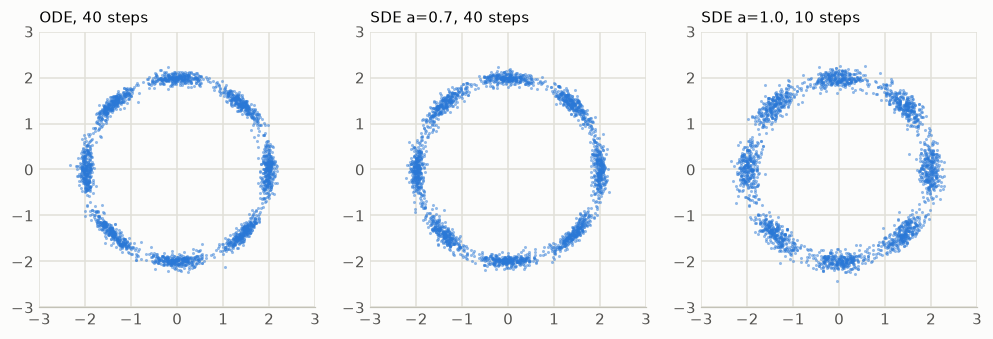

In [5]:
panels = ["ODE, 40 steps", "SDE a=0.7, 40 steps", "SDE a=1.0, 10 steps"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), dpi=110, facecolor=SURFACE)
for ax, name in zip(axes, panels):
    x = rows[name][::8]
    style(ax, grid="both")
    ax.scatter(x[:, 0], x[:, 1], s=4, color=COLORS[0], alpha=0.5, lw=0)
    ax.set_aspect("equal")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(name, loc="left", fontsize=10)
plt.show()

At 40 steps the SDE gives the same distribution as the ODE at every noise level: radius std 0.076-0.077 against 0.074.

At 10 steps it does not. Radius std is 0.061 for the ODE, 0.093 at a=0.7 and 0.112 at a=1.0. The step is exact only for small dt, with 10 steps the added noise is not fully removed.

## Along the way

Same starting noise for both, 40 steps, std of all coordinates and mean radius at a few t.

In [6]:
torch.manual_seed(1)
noise = torch.randn(len(c), 2)
ode = sample(base, c, 40, 0, noise, keep=True)
sde = sample(base, c, 40, 0.7, noise, keep=True)

print(f"{'t':<6}{'ODE std':>9}{'SDE std':>9}{'ODE radius':>12}{'SDE radius':>12}")
for i in (0, 10, 20, 30, 40):
    print(
        f"{1 - i / 40:<6.2f}{ode[i].std().item():>9.3f}{sde[i].std().item():>9.3f}"
        f"{ode[i].norm(dim=1).mean().item():>12.3f}{sde[i].norm(dim=1).mean().item():>12.3f}"
    )

t       ODE std  SDE std  ODE radius  SDE radius
1.00      1.003    1.003       1.257       1.257
0.75      0.829    0.859       1.043       1.080
0.50      0.865    0.879       1.134       1.148
0.25      1.090    1.093       1.520       1.523
0.00      1.414    1.414       1.998       1.999


Close at every t. The biggest gap is early (0.86 against 0.83 at t=0.75), where the noise added per step is largest.

## Notes for later

- the step works and the log-prob is right, this goes into the RL loop as is
- at 10 steps the SDE samples are wider than the ODE ones. Training sees noisier samples than evaluation does. Should be fine as long as the reward still ranks them correctly
- for SD3 the same two checks apply: noise 0 must give the normal image, and the ratio must be exactly 1 before the first update